###Exploring data : EDA

In [2]:
import pandas as pd
import numpy as np
import os

1. **Initiale exploring with ydata profiling**

In [ ]:
!pip install ydata_profiling


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 23.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 679.7/679.7 kB 38.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 6.0 MB/s eta 0:00:00


In [ ]:
import pandas as pd
from ydata_profiling import ProfileReport

# Charger le dataset
df = pd.read_csv("/content/drive/MyDrive/PFE/clean1.csv")

# Générer le dashboard automatique
profile = ProfileReport(
    df,
    title="Dashboard de description du dataset",
    explorative=True
)

# Export en HTML
profile.to_file("/content/drive/MyDrive/PFE/dashboard_dataset.html")


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 23/23 [00:00<00:00, 24.58it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

2.  **Detailed exploration of features and targets to decide about MLT and feature engineering**

In [3]:
df = pd.read_csv(r"D:\Mes projets\PFE\Project\data\features\clean2.csv")
# Vérifier cette hypothèse
mask_sel_nan = df["performance.selectivite_pct"].isna()
print(df.loc[mask_sel_nan, "performance.produit_majoritaire"].value_counts())
# Si CO domine → les MOFs mono-produit ne reportent pas la sélectivité

performance.produit_majoritaire
CO          99
HCOOH       15
CH3OH       14
CH4         10
H2           4
mixte        3
H2O2         2
C2H6         1
CH3CH2OH     1
Name: count, dtype: int64


Les MOFs CO-sélectifs reportent rarement la sélectivité car CO est souvent le seul produit détecté. L' hypothèse MNAR est confirmée : "70.3% manquants : c'est MNAR par définition. Les auteurs ne reportent la sélectivité que quand ils ont plusieurs produits compétiteurs. Quand un seul produit est détecté → sélectivité implicitement 100% mais non reportée."

In [4]:
# Vérifier les suspects immédiatement
seuil = df["performance.taux_production_umol_g_h"].quantile(0.99)
print(seuil)  # probablement autour de 50 000

suspects = df[df["performance.taux_production_umol_g_h"] > seuil]
print(suspects[["mof.metal", "mof.ligand", 
                 "performance.taux_production_umol_g_h"]].to_string())

18265.299999999956
    mof.metal mof.ligand  performance.taux_production_umol_g_h
156     Fe/Mn     H4abtc                               21510.0
157     Fe/Zn     H4abtc                               19450.0
191        Ni        BDC                              104000.0


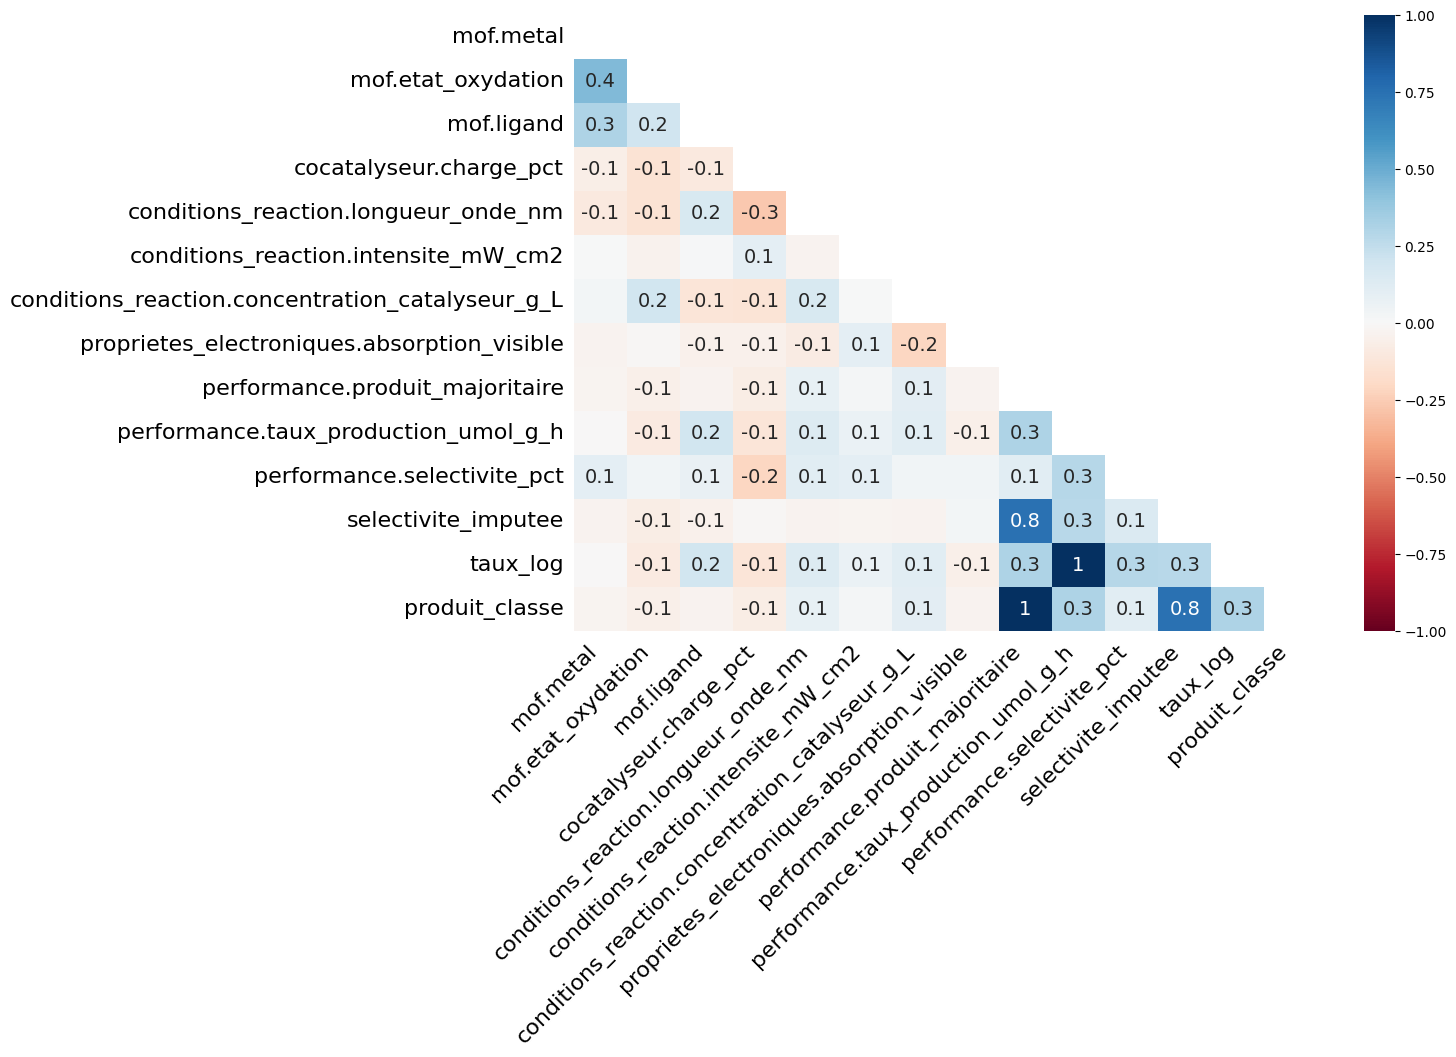

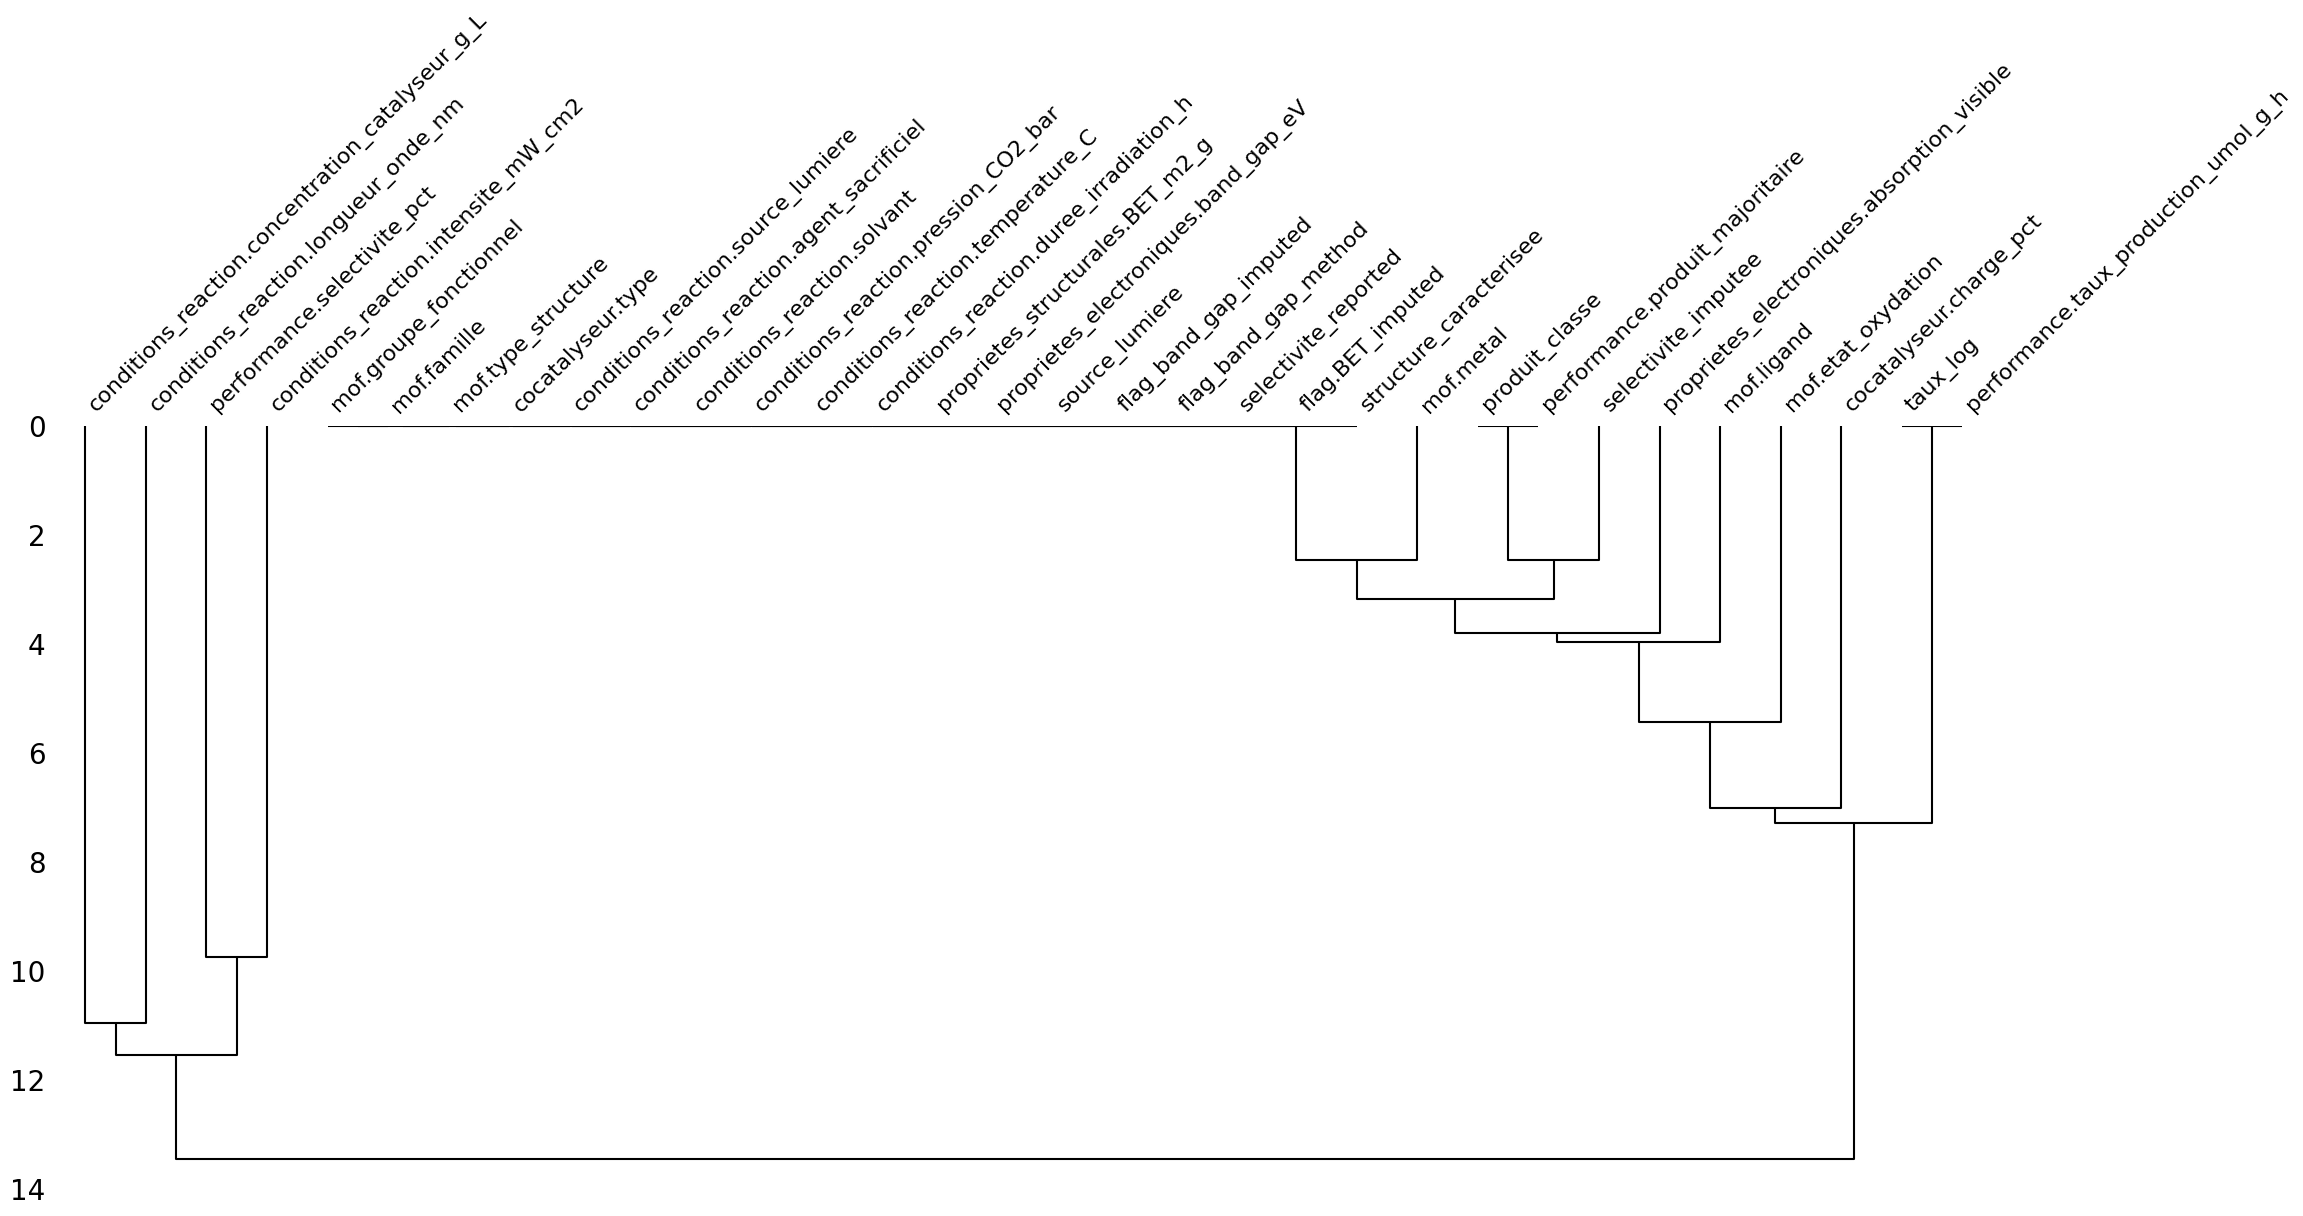

In [13]:
import missingno as msno
import matplotlib.pyplot as plt

# Corrélation entre patterns de manquants
msno.heatmap(df, figsize=(12, 8))
plt.savefig(r"D:\Mes projets\PFE\Project\data\features\mnar_heatmap.png")
# → Révèle si band_gap manque toujours avec HOMO/LUMO (confirmé)
# → Révèle si sélectivité manque avec certains produits

# Dendrogramme des manquants
msno.dendrogram(df)
plt.savefig(r"D:\Mes projets\PFE\Project\data\features\mnar_dendro.png")

Corrélations faibles partout (max 0,4) — c'est normal et attendu en chimie des MOFs. La performance photocatalytique dépend d'interactions non-linéaires complexes, et non de relations linéaires simples. Ceci valide notre choix MTL car un modèle linéaire n'aurait aucune chance ici.
metal ↔ etat_oxydation : 0.4   : logique, chaque métal a ses états préférés
metal ↔ ligand : 0.3            : certains ligands sont synthétisés avec certains métaux
BET ↔ longueur_onde : -0.1     : faible, pas de multicolinéarité problématique
selectivite_imputee ↔ selectivite_pct : 0.5  : la méthode d'imputation est cohérente
Aucune suppression pour multicolinéarité — aucune paire ne dépasse 0,5. Tu gardes tout.

Ce que le dendrogramme MNAR révèle
Deux clusters distincts très clairs :
Cluster gauche (distance ~10-11) : selectivite_pct, taux_production, BET, intensite, concentration, longueur_onde, ligand, famille, type, cocatalyseur, agent_sacrificiel, conditions réaction
* Ces features manquent indépendamment les unes des autres — MCAR/MAR classique
Cluster droit (distance ~2-3, très proches) : flag_band_gap, band_gap_imputed, selectivite_imputee, taux_production, produit_majoritaire, metal, etat_oxydation, absorption_visible
* Ces features manquent ensemble — confirme le MNAR structurel des propriétés électroniques
Décision MTL : Le cluster droit confirme que band_gap_reported est un signal réel — on doit le garder comme feature.

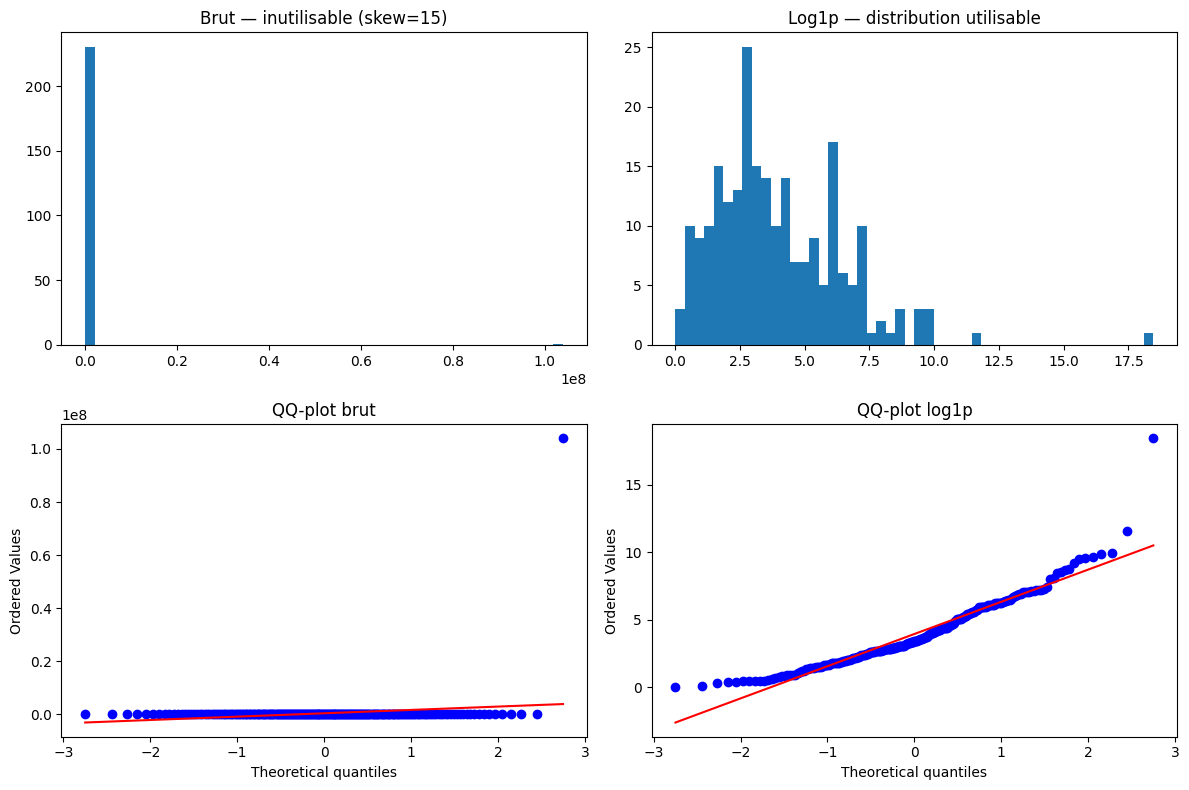

In [11]:
from scipy import stats

taux = df["performance.taux_production_umol_g_h"].dropna()
taux = taux[taux > 0]  # exclure les zéros

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Brut
axes[0,0].hist(taux, bins=50)
axes[0,0].set_title("Brut — inutilisable (skew=15)")

# Log1p
axes[0,1].hist(np.log1p(taux), bins=50)
axes[0,1].set_title("Log1p — distribution utilisable")

# QQ-plot brut
stats.probplot(taux, dist="norm", plot=axes[1,0])
axes[1,0].set_title("QQ-plot brut")

# QQ-plot log
stats.probplot(np.log1p(taux), dist="norm", plot=axes[1,1])
axes[1,1].set_title("QQ-plot log1p")

plt.tight_layout()
plt.savefig(r"D:\Mes projets\PFE\Project\data\features\log_normalite.png")

QQ-plot brut  : déviation massive → distribution inutilisable
QQ-plot log1p : quasi-linéaire sauf queues extrêmes → log1p validé 
Alors c'est la colone log1p qui va entrer dans MLT pas la brute

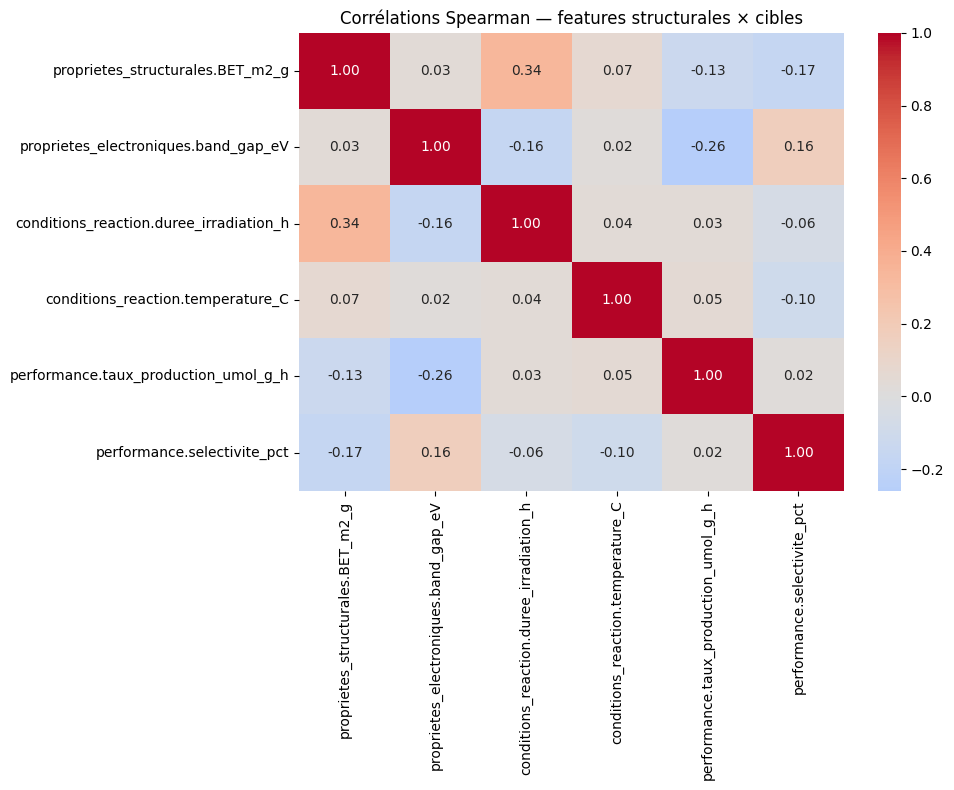

In [9]:
# Spearman car distributions non-normales
df = pd.read_csv(r"D:\Mes projets\PFE\Project\data\features\clean2.csv")
cols = [
    "proprietes_structurales.BET_m2_g",
    "proprietes_electroniques.band_gap_eV",
    "conditions_reaction.duree_irradiation_h",
    "conditions_reaction.temperature_C",
    "performance.taux_production_umol_g_h",
    "performance.selectivite_pct"
]

corr = df[cols].corr(method="spearman")

import seaborn as sns
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Corrélations Spearman — features structurales × cibles")
plt.tight_layout()
plt.savefig(r"D:\Mes projets\PFE\Project\data\features\spearman_cibles.png")

BET ↔ durée_irradiation : 0.34      ← corrélation expérimentale (biais de publication)
BET ↔ température : 0.20            ← idem
band_gap ↔ taux_production : -0.27  ← signal physique réel : les MOFs avec un petit band gap (meilleure absorption visible) produisent plus. C'est exactement la physique attendue. Ce signal doit être préservé dans ton MTL.
band_gap ↔ sélectivité : 0.17       ← avant imputation c'était 0.22 (note en bas)
taux_production ↔ sélectivité : 0.02 ← quasi nul

Les deux cibles sont quasi-indépendantes statistiquement.
→ Le tronc partagé MTL doit apprendre deux choses différentes.
→ Envisageant  2 couches par têtes
    taux_production ↔ sélectivité à 0.02 — c'est le signal le plus important de cette figure pour l' architecture MTL. Deux cibles quasi-indépendantes statistiquement signifient que le tronc partagé ne peut pas "tricher" en apprenant une seule représentation qui satisfait les deux. Il doit apprendre une représentation vraiment commune de la physique MOF.

In [8]:
counts = df["performance.produit_majoritaire"].value_counts()
print(counts)
print(f"\nRatio CO/C2H6 : {counts['CO'] / counts['C2H6']:.0f}x")
# → CO 99x, C2H6 1x = ratio 99:1 → très déséquilibré

# Décision : class_weight dans la loss MTL
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = df["performance.produit_majoritaire"].dropna().unique()
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=df["performance.produit_majoritaire"].dropna()
)
class_weight_dict = dict(zip(classes, weights))
print(class_weight_dict)
# → À passer dans la CrossEntropyLoss MTL

performance.produit_majoritaire
CO          139
HCOOH        30
CH4          28
CH3OH        16
H2            7
mixte         7
H2O2          2
C2H6          2
CH3CH2OH      2
C2H4          1
Name: count, dtype: int64

Ratio CO/C2H6 : 70x
{'CO': np.float64(0.1683453237410072), 'HCOOH': np.float64(0.78), 'CH3OH': np.float64(1.4625), 'CH4': np.float64(0.8357142857142857), 'H2': np.float64(3.342857142857143), 'mixte': np.float64(3.342857142857143), 'H2O2': np.float64(11.7), 'C2H6': np.float64(11.7), 'CH3CH2OH': np.float64(11.7), 'C2H4': np.float64(23.4)}


Ratio CO/C2H4 = 139x. C'est trop déséquilibré pour une classification à 10 classes.
Décision pour MT — regroupement des classes 

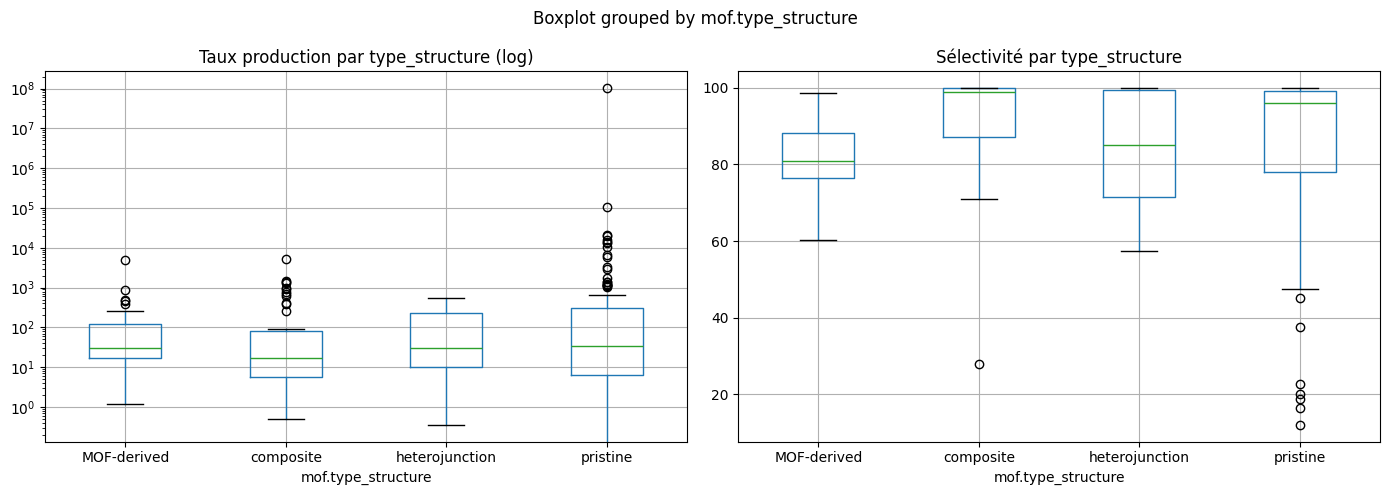

In [10]:
#  croiser features et cibles par groupe
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df.boxplot(
    column="performance.taux_production_umol_g_h",
    by="mof.type_structure",
    ax=axes[0]
)
axes[0].set_yscale("log")
axes[0].set_title("Taux production par type_structure (log)")

df.boxplot(
    column="performance.selectivite_pct",
    by="mof.type_structure",
    ax=axes[1]
)
axes[1].set_title("Sélectivité par type_structure")

plt.tight_layout()
plt.savefig(r"D:\Mes projets\PFE\Project\data\features\performance_par_type.png")

taux de conversion
pristine      : médiane ~10³, grande variance, outliers hauts
MOF-derived   : médiane ~10², plus stable
composite     : médiane ~10², similaire MOF-derived
heterojunction: médiane ~10², mais outliers très hauts
Sélectivité :
MOF-derived   : médiane ~85%, variance modérée
composite     : médiane ~90%, bonne sélectivité
heterojunction: médiane ~90%, mais outliers très bas (~25%)
pristine      : médiane ~95%, mais outliers à 0% (probablement H2 pur)
Décision feature engineering : type_structure est informatif pour les deux cibles.

    #####MLT
Loss sélectivitéMasque obligatoire (70% manquants)Loss classificationclass_weight sur 4 classes regroupées

Sélectivité observée : 85/286 lignes (29.7%)
Stats : min=12.0  median=96.0  max=100.0  std=22.9

Figure sauvegardée → D:\Mes projets\PFE\Project\data\features\selectivite_distribution.png


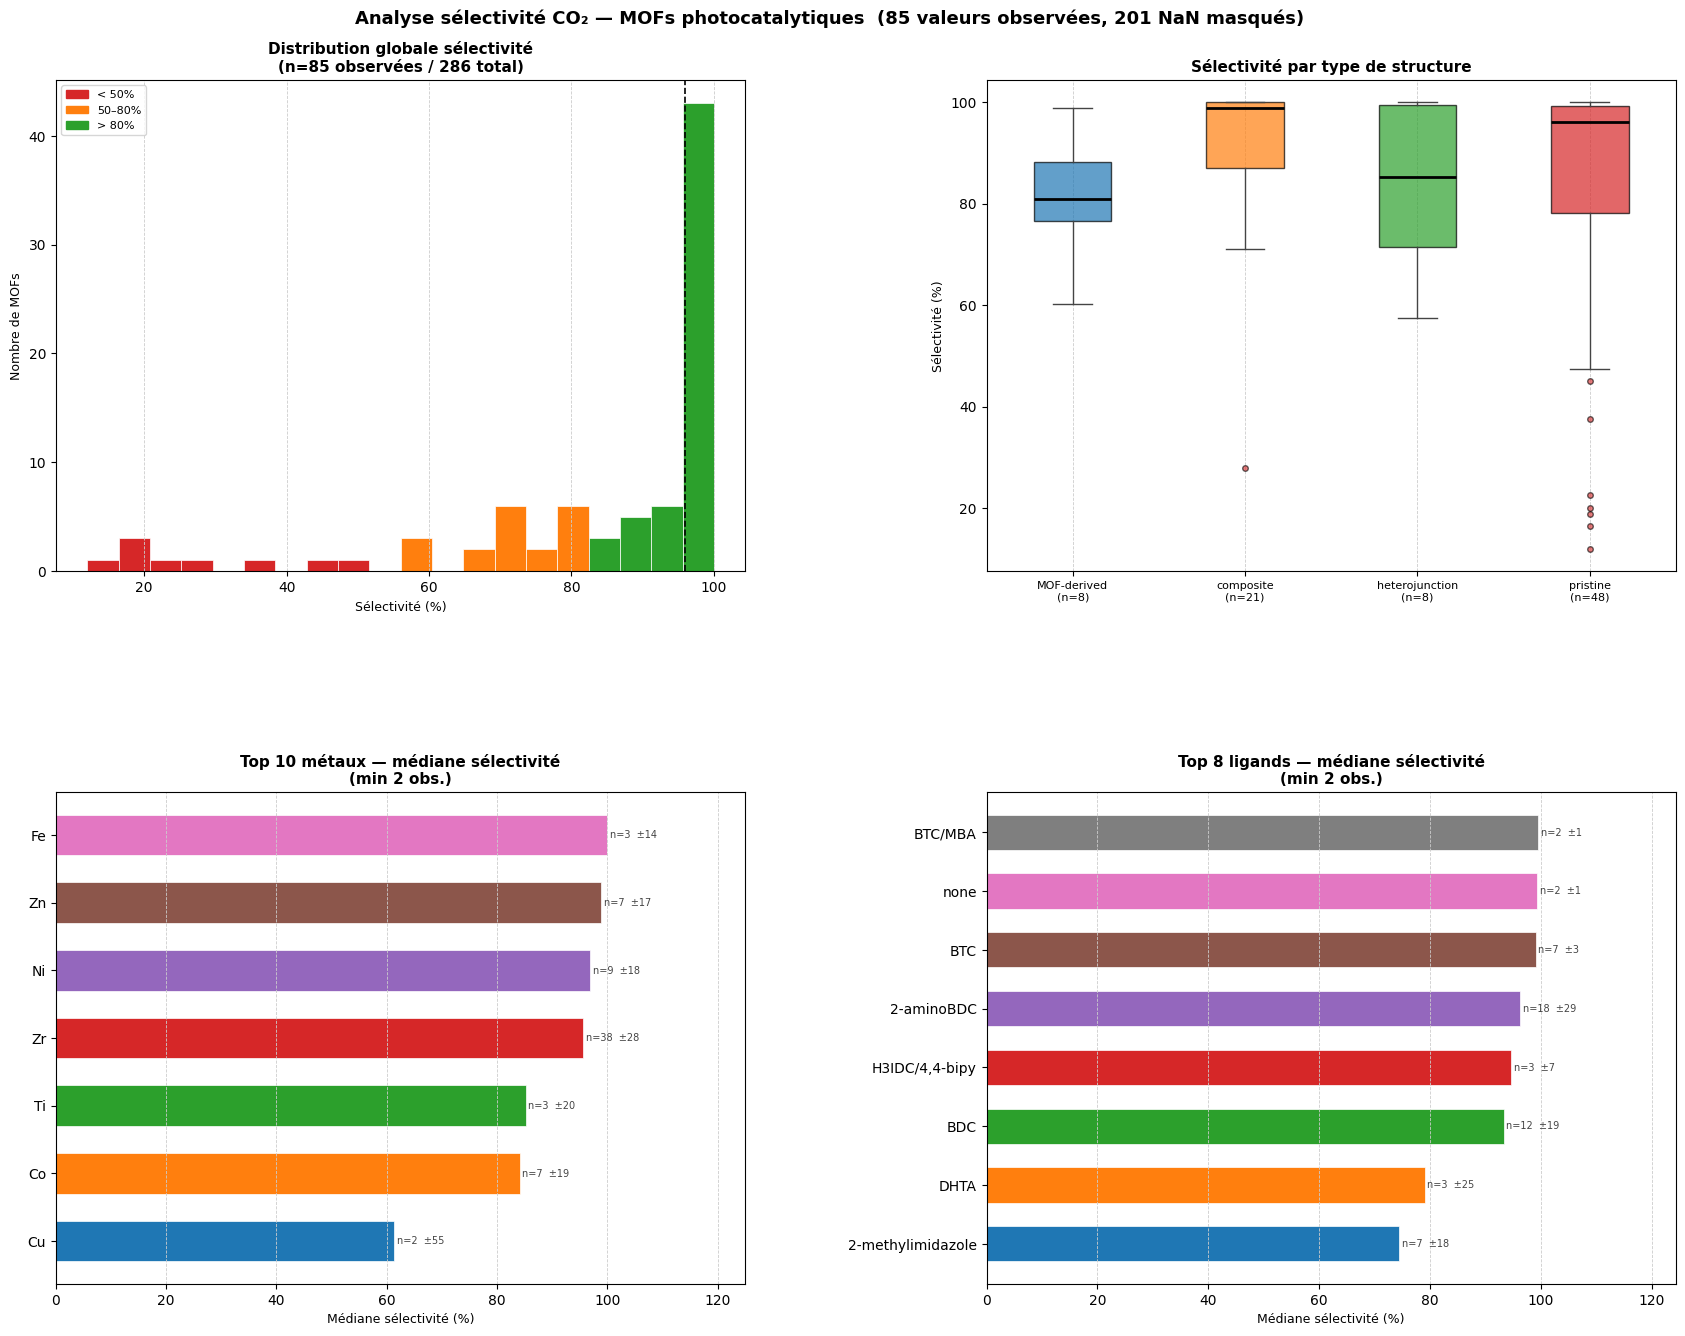


── Résumé par type_structure ──
                    count  median  mean   std   min    max
mof.type_structure                                        
MOF-derived             8    81.0  81.2  13.4  60.2   98.8
composite              21    98.9  89.3  17.5  28.0  100.0
heterojunction          8    85.2  83.4  17.3  57.4  100.0
pristine               48    96.1  82.0  26.9  12.0  100.0

── Top métaux (médiane desc) ──
           count  median   std
mof.metal                     
Fe             3   100.0  14.2
Zn             7    98.9  16.7
Ni             9    96.8  17.9
Zr            38    95.6  27.9
Ti             3    85.2  20.0
Co             7    84.1  18.6
Cu             2    61.3  54.7


In [5]:
"""
Visualisation distribution sélectivité CO2
par type_structure, métal (top), ligand (top)
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch

INPUT     = r"D:\Mes projets\PFE\Project\data\features\clean2.csv"
OUTPUT_FIG = r"D:\Mes projets\PFE\Project\data\features\selectivite_distribution.png"

df = pd.read_csv(INPUT)

SEL_COL = "performance.selectivite_pct"
df_sel  = df[df[SEL_COL].notna()].copy()
df_sel[SEL_COL] = pd.to_numeric(df_sel[SEL_COL], errors="coerce")
df_sel  = df_sel[df_sel[SEL_COL].notna()]

n_total = len(df)
n_obs   = len(df_sel)
print(f"Sélectivité observée : {n_obs}/{n_total} lignes ({n_obs/n_total*100:.1f}%)")
print(f"Stats : min={df_sel[SEL_COL].min():.1f}  "
      f"median={df_sel[SEL_COL].median():.1f}  "
      f"max={df_sel[SEL_COL].max():.1f}  "
      f"std={df_sel[SEL_COL].std():.1f}\n")

PALETTE      = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728",
                "#9467bd", "#8c564b", "#e377c2", "#7f7f7f"]
TOP_N_METAL  = 10
TOP_N_LIGAND = 8

fig = plt.figure(figsize=(18, 14))
gs  = gridspec.GridSpec(2, 2, figure=fig,
                        hspace=0.45, wspace=0.35,
                        left=0.07, right=0.97,
                        top=0.92, bottom=0.06)

# ═══════════════════════════════════════════════════════════
# 1. Histogramme global
# ═══════════════════════════════════════════════════════════
ax1 = fig.add_subplot(gs[0, 0])

vals = df_sel[SEL_COL].values
counts, bins, patches = ax1.hist(vals, bins=20, edgecolor="white", linewidth=0.5)

for patch, left in zip(patches, bins[:-1]):
    if left < 50:
        patch.set_facecolor("#d62728")
    elif left < 80:
        patch.set_facecolor("#ff7f0e")
    else:
        patch.set_facecolor("#2ca02c")

ax1.axvline(df_sel[SEL_COL].median(), color="black",
            linestyle="--", linewidth=1.2,
            label=f"Médiane = {df_sel[SEL_COL].median():.0f}%")

legend_patches = [
    Patch(color="#d62728", label="< 50%"),
    Patch(color="#ff7f0e", label="50–80%"),
    Patch(color="#2ca02c", label="> 80%"),
]
ax1.legend(handles=legend_patches, fontsize=8)
ax1.set_title(f"Distribution globale sélectivité\n"
              f"(n={n_obs} observées / {n_total} total)", fontsize=11, fontweight="bold")
ax1.set_xlabel("Sélectivité (%)", fontsize=9)
ax1.set_ylabel("Nombre de MOFs", fontsize=9)
ax1.grid(axis="x", linestyle="--", linewidth=0.6, color="#cccccc")

# ═══════════════════════════════════════════════════════════
# 2. Boxplot par type_structure
# ═══════════════════════════════════════════════════════════
ax2 = fig.add_subplot(gs[0, 1])

TYPE_COL = "mof.type_structure"
if TYPE_COL in df_sel.columns:
    groups     = df_sel.groupby(TYPE_COL)[SEL_COL].apply(list)
    labels     = list(groups.index)
    data       = list(groups.values)
    counts_grp = df_sel[TYPE_COL].value_counts()

    bp = ax2.boxplot(data, patch_artist=True, vert=True,
                     medianprops=dict(color="black", linewidth=2),
                     whiskerprops=dict(color="#444444"),
                     capprops=dict(color="#444444"),
                     flierprops=dict(marker="o", markerfacecolor="#d62728",
                                     markersize=4, alpha=0.6))
    for patch, color in zip(bp["boxes"], PALETTE):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)

    xlabels = [f"{l}\n(n={counts_grp.get(l, 0)})" for l in labels]
    ax2.set_xticks(range(1, len(labels) + 1))
    ax2.set_xticklabels(xlabels, fontsize=8)
    ax2.set_title("Sélectivité par type de structure", fontsize=11, fontweight="bold")
    ax2.set_ylabel("Sélectivité (%)", fontsize=9)
    ax2.grid(axis="x", linestyle="--", linewidth=0.6, color="#cccccc")

# ═══════════════════════════════════════════════════════════
# 3. Barplot horizontal — Top métaux par médiane sélectivité
# ═══════════════════════════════════════════════════════════
ax3 = fig.add_subplot(gs[1, 0])

METAL_COL = "mof.metal"
if METAL_COL in df_sel.columns:
    metal_stats = (df_sel.groupby(METAL_COL)[SEL_COL]
                   .agg(median="median", count="count", std="std")
                   .query("count >= 2")
                   .sort_values("median", ascending=True)
                   .tail(TOP_N_METAL))

    colors_metal = [PALETTE[i % len(PALETTE)] for i in range(len(metal_stats))]
    bars = ax3.barh(metal_stats.index, metal_stats["median"],
                    color=colors_metal, edgecolor="white",
                    linewidth=0.5, height=0.6)

    for bar, (idx, row) in zip(bars, metal_stats.iterrows()):
        std_str = f"±{row['std']:.0f}" if not np.isnan(row["std"]) else ""
        ax3.text(bar.get_width() + 0.5,
                 bar.get_y() + bar.get_height() / 2,
                 f"n={int(row['count'])}  {std_str}",
                 va="center", ha="left", fontsize=7, color="#444444")

    ax3.set_title(f"Top {TOP_N_METAL} métaux — médiane sélectivité\n(min 2 obs.)",
                  fontsize=11, fontweight="bold")
    ax3.set_xlabel("Médiane sélectivité (%)", fontsize=9)
    ax3.set_xlim(0, metal_stats["median"].max() * 1.25)
    ax3.grid(axis="x", linestyle="--", linewidth=0.6, color="#cccccc")

# ═══════════════════════════════════════════════════════════
# 4. Barplot horizontal — Top ligands par médiane sélectivité
# ═══════════════════════════════════════════════════════════
ax4 = fig.add_subplot(gs[1, 1])

LIGAND_COL = "mof.ligand"
if LIGAND_COL in df_sel.columns:
    ligand_stats = (df_sel.groupby(LIGAND_COL)[SEL_COL]
                    .agg(median="median", count="count", std="std")
                    .query("count >= 2")
                    .sort_values("median", ascending=True)
                    .tail(TOP_N_LIGAND))

    colors_ligand = [PALETTE[i % len(PALETTE)] for i in range(len(ligand_stats))]
    bars = ax4.barh(ligand_stats.index, ligand_stats["median"],
                    color=colors_ligand, edgecolor="white",
                    linewidth=0.5, height=0.6)

    for bar, (idx, row) in zip(bars, ligand_stats.iterrows()):
        std_str = f"±{row['std']:.0f}" if not np.isnan(row["std"]) else ""
        ax4.text(bar.get_width() + 0.5,
                 bar.get_y() + bar.get_height() / 2,
                 f"n={int(row['count'])}  {std_str}",
                 va="center", ha="left", fontsize=7, color="#444444")

    ax4.set_title(f"Top {TOP_N_LIGAND} ligands — médiane sélectivité\n(min 2 obs.)",
                  fontsize=11, fontweight="bold")
    ax4.set_xlabel("Médiane sélectivité (%)", fontsize=9)
    ax4.set_xlim(0, ligand_stats["median"].max() * 1.25)
    ax4.grid(axis="x", linestyle="--", linewidth=0.6, color="#cccccc")

# ── Titre global ──────────────────────────────────────────
fig.suptitle(
    f"Analyse sélectivité CO₂ — MOFs photocatalytiques  "
    f"({n_obs} valeurs observées, {n_total - n_obs} NaN masqués)",
    fontsize=13, fontweight="bold", y=0.97
)

plt.savefig(OUTPUT_FIG, dpi=150, bbox_inches="tight")
print(f"Figure sauvegardée → {OUTPUT_FIG}")
plt.show()

# ── Résumé textuel ────────────────────────────────────────
print("\n── Résumé par type_structure ──")
if TYPE_COL in df_sel.columns:
    print(df_sel.groupby(TYPE_COL)[SEL_COL]
          .agg(["count", "median", "mean", "std", "min", "max"])
          .round(1).to_string())

print("\n── Top métaux (médiane desc) ──")
if METAL_COL in df_sel.columns:
    print(df_sel.groupby(METAL_COL)[SEL_COL]
          .agg(count="count", median="median", std="std")
          .query("count >= 2")
          .sort_values("median", ascending=False)
          .head(10).round(1).to_string())